# Modern classical and compact deep-learning comparators


**Scientific goal.** Test whether appropriate modern classical or compact neural models improve on the baseline reference. **Input from Notebook 03.** The immutable folds, baseline OOF evidence, and strongest baseline. **Allowed data.** The same outer-training/inner-validation partitions and predictor contract. **Methods.** GPR, XGBoost, LightGBM, CatBoost when available, MultiTask MLP, Residual MLP, and compact FT-Transformer with training-only early stopping and three seeds. **Output to Notebook 05.** Comparable OOF predictions, learning curves, seed stability, timing, and error patterns for component design.


## 1. Environment, hardware, and modeling contract

In [1]:
from pathlib import Path
import hashlib
import json
import os
import platform
import sys
import time
import warnings

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

warnings.filterwarnings("ignore")
SEED = 20260820
REQUIRED_FONT = "Times New Roman"
FONT_SIZE_MIN = 16
FONT_SIZE_MAX = 18
FIGURE_DPI = 350
RUN_ID = "FA_ATF_DaKS69_Exploratory_20260820"

ROOT = Path.cwd().resolve()
if not (ROOT / "dataset").exists() and (ROOT.parent / "dataset").exists():
    ROOT = ROOT.parent

RAW_DIR = ROOT / "dataset" / "raw"
UNIFIED_DIR = ROOT / "dataset" / "unified"
RUN_ROOT = ROOT / "artifacts" / RUN_ID
TABLE_ROOT = RUN_ROOT / "Tables"
FIGURE_PNG_DIR = RUN_ROOT / "Figures" / "PNG"
FIGURE_PDF_DIR = RUN_ROOT / "Figures" / "PDF"
FIGURE_SOURCE_DIR = RUN_ROOT / "Tables" / "Figure_Source_Data"
REPORT_DIR = RUN_ROOT / "Reports"
MANIFEST_DIR = RUN_ROOT / "Manifests"
MODEL_DIR = RUN_ROOT / "Models"
PREDICTION_DIR = RUN_ROOT / "Tables" / "Predictions"
METRIC_DIR = RUN_ROOT / "Tables" / "Metrics"
STATISTICS_DIR = RUN_ROOT / "Tables" / "Statistics"
AUDIT_DIR = RUN_ROOT / "Tables" / "Audit"

for directory in (
    RAW_DIR, UNIFIED_DIR, RUN_ROOT, TABLE_ROOT, FIGURE_PNG_DIR, FIGURE_PDF_DIR,
    FIGURE_SOURCE_DIR, REPORT_DIR, MANIFEST_DIR, MODEL_DIR, PREDICTION_DIR,
    METRIC_DIR, STATISTICS_DIR, AUDIT_DIR,
):
    directory.mkdir(parents=True, exist_ok=True)


In [2]:
available_fonts = {font.name for font in font_manager.fontManager.ttflist}
if REQUIRED_FONT not in available_fonts:
    raise RuntimeError("Times New Roman is unavailable; publication figures cannot be generated.")

mpl.rcParams.update({
    "font.family": REQUIRED_FONT,
    "font.serif": [REQUIRED_FONT],
    "mathtext.fontset": "custom",
    "mathtext.rm": REQUIRED_FONT,
    "mathtext.it": REQUIRED_FONT + ":italic",
    "mathtext.bf": REQUIRED_FONT + ":bold",
    "font.size": 16,
    "axes.titlesize": 18,
    "axes.labelsize": 17,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "legend.fontsize": 16,
    "figure.titlesize": 18,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.linewidth": 1.0,
    "lines.linewidth": 2.0,
    "figure.dpi": FIGURE_DPI,
    "savefig.dpi": FIGURE_DPI,
    "figure.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.facecolor": "white",
    "axes.grid": True,
    "grid.color": "#E7EAED",
    "grid.alpha": 0.80,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

PALETTE = {
    "blue": "#2F6B8F", "orange": "#C77C2B", "green": "#4F7F3A",
    "purple": "#6D5A8D", "red": "#B45A55", "gray": "#6E7378",
    "light_gray": "#E7EAED", "teal": "#4A8C8A", "gold": "#C9A227",
    "black": "#222222", "white": "#FFFFFF",
}

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

def validate_figure_typography(fig):
    fig.canvas.draw()
    violations = []
    for text_object in fig.findobj(match=mpl.text.Text):
        if not text_object.get_text().strip():
            continue
        size = float(text_object.get_fontsize())
        resolved_name = text_object.get_fontproperties().get_name()
        if resolved_name != REQUIRED_FONT:
            violations.append(f"font={resolved_name!r}: {text_object.get_text()!r}")
        if not (FONT_SIZE_MIN <= size <= FONT_SIZE_MAX):
            violations.append(f"fontsize={size}: {text_object.get_text()!r}")
    if violations:
        raise AssertionError("Typography QA failed:\n" + "\n".join(violations))

def save_scientific_figure(fig, stem, source_frame):
    source_path = FIGURE_SOURCE_DIR / f"{stem}.csv"
    png_path = FIGURE_PNG_DIR / f"{stem}.png"
    source_frame.to_csv(source_path, index=False)
    validate_figure_typography(fig)
    fig.savefig(png_path, dpi=FIGURE_DPI, bbox_inches="tight", pad_inches=0.08, facecolor="white")
    return png_path, None, source_path

import pickle


In [3]:
# Publication-table presentation helper. It changes display only; values are untouched.
def display_grouped_table(
    frame,
    title=None,
    identifier_columns=None,
    column_groups=None,
    row_group_columns=None,
    max_rows_per_block=12,
):
    table = frame.copy()

    def _identifier_columns(columns):
        priorities = [
            "model", "model_family", "rank", "target", "Target", "variant", "Variant",
            "ablation", "comparison", "Comparison", "comparator", "Comparator",
            "class", "Class", "factor", "factor_label", "level", "condition",
            "distance_band", "metric", "Metric", "component",
            "candidate", "expert", "outer_fold", "inner_fold", "fold",
            "Feature", "feature", "Predictor", "predictor", "Variable",
            "variable", "Field", "Decision", "Analysis item", "Scientific conclusion",
            "Scientific property", "Quantity", "Scaler", "Contract item", "criterion",
            "Column", "item", "sample_id", "specimen_id", "section_id",
        ]
        selected = [column for column in priorities if column in columns]
        return selected[:4]

    def _column_groups(columns, identifiers):
        remaining = [column for column in columns if column not in identifiers]
        if len(columns) <= 7:
            return [("Complete table", remaining)]
        rules = [
            ("Predictors and design variables", (
                "hv_init", "feed", "cutting_speed", "depth_of_cut", "uncut_chip",
                "material_removal", "theoretical_roughness", "predictor", "factor",
                "formula", "unit", "level", "role", "definition", "available",
            )),
            ("Measured responses", (
                "surface_roughness", "post_process_hardness", "y_true", "y_pred",
                "lower_90", "upper_90",
            )),
            ("Predictive performance", (
                "mae", "rmse", "nrmse", "r2", "macro", "bias", "error",
                "rank", "score",
            )),
            ("Uncertainty and statistical evidence", (
                "ci_", "_ci", "confidence", "bootstrap", "coverage", "interval",
                "wilcoxon", "holm", "p_value", "_p", "probability", "effect",
                "delta", "median_fold", "sign_flip", "quantile",
            )),
            ("Computational efficiency", (
                "time", "latency", "parameter", "memory", "byte", "epoch",
                "inference", "fit_seconds", "complexity",
            )),
            ("Sample, fold, and provenance", (
                "observation", "specimen", "sample", "section", "fold", "seed",
                "rows", "columns", "matrix_rank", "condition_number", "replicate",
                "minimum", "maximum", "median", "mean", "std", "sd", "skew",
                "count", "n_", "status", "retained", "selected", "interpretation",
                "requirement", "evidence", "value",
            )),
        ]
        assigned = set()
        grouped = []
        for label, tokens in rules:
            members = [
                column for column in remaining
                if column not in assigned
                and any(token in str(column).lower() for token in tokens)
            ]
            if members:
                grouped.append((label, members))
                assigned.update(members)
        leftovers = [column for column in remaining if column not in assigned]
        if leftovers:
            grouped.append(("Additional reported attributes", leftovers))
        return grouped or [("Complete table", remaining)]

    def _split_wide_groups(groups):
        split_groups = []
        for label, columns in groups:
            if len(columns) <= 5:
                split_groups.append((label, columns))
                continue
            part_count = (len(columns) + 4) // 5
            for part_index in range(part_count):
                start = part_index * 5
                split_groups.append((
                    f"{label} (part {part_index + 1}/{part_count})",
                    columns[start:start + 5],
                ))
        return split_groups

    identifiers = (
        [column for column in identifier_columns if column in table.columns]
        if identifier_columns is not None
        else _identifier_columns(list(table.columns))
    )
    groups = (
        [(label, [column for column in columns if column in table.columns])
         for label, columns in column_groups]
        if column_groups is not None
        else _column_groups(list(table.columns), identifiers)
    )
    groups = _split_wide_groups([(label, columns) for label, columns in groups if columns])

    represented = set(identifiers)
    for _, columns in groups:
        represented.update(columns)
    missing = [column for column in table.columns if column not in represented]
    if missing:
        groups.extend(_split_wide_groups([("Additional reported attributes", missing)]))
    assert represented.union(missing) == set(table.columns)

    if row_group_columns is None and len(table) > max_rows_per_block:
        candidates = [
            "model_family", "target", "factor", "condition", "distance_band",
            "Role", "role", "component", "outer_fold", "variant", "comparator",
        ]
        row_group_columns = []
        for column in candidates:
            if column not in table.columns or column in row_group_columns:
                continue
            unique_count = table[column].nunique(dropna=False)
            if 1 < unique_count <= 10:
                row_group_columns.append(column)
                largest = table.groupby(row_group_columns, dropna=False, sort=False).size().max()
                if largest <= max_rows_per_block:
                    break
    row_group_columns = [
        column for column in (row_group_columns or []) if column in table.columns
    ]
    if row_group_columns:
        row_groups = list(table.groupby(row_group_columns, dropna=False, sort=False))
    elif len(table) > max_rows_per_block:
        row_groups = []
        for start in range(0, len(table), max_rows_per_block):
            stop = min(start + max_rows_per_block, len(table))
            noun = "models" if "model" in table.columns else "records"
            row_groups.append((
                f"{noun} {start + 1}-{stop} in displayed order",
                table.iloc[start:stop],
            ))
    else:
        row_groups = [(None, table)]

    for row_key, row_part in row_groups:
        if row_group_columns:
            values = row_key if isinstance(row_key, tuple) else (row_key,)
            row_label = "; ".join(
                f"{column}={value}" for column, value in zip(row_group_columns, values)
            )
        else:
            row_label = row_key
        for group_label, columns in groups:
            selected_columns = list(dict.fromkeys(identifiers + columns))
            heading = " — ".join(
                item for item in (title, row_label, group_label) if item
            )
            display(Markdown(f"**{heading or 'Complete table'}**"))
            with pd.option_context(
                "display.max_rows", len(row_part),
                "display.max_columns", len(selected_columns),
                "display.max_colwidth", None,
                "display.width", None,
            ):
                display(row_part[selected_columns].style.hide(axis="index"))


def display_complete_table(frame, title=None):
    """Backward-compatible alias for table cells colocated with unchanged figures."""
    return display_grouped_table(frame, title=title)

import random
import joblib
import scipy
import sklearn
from sklearn.base import clone
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, RBF, WhiteKernel
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

DATA_PATH = UNIFIED_DIR / "modeling_dataset.csv"
data = pd.read_csv(DATA_PATH)
FEATURES = [
    "HV_init_HV30", "feed_mm_rev", "cutting_speed_m_min", "depth_of_cut_mm",
    "uncut_chip_section_mm2", "material_removal_proxy_mm3_min", "theoretical_roughness_Ra_um",
]


TARGETS = ["surface_roughness_Ra_um", "post_process_hardness_HV30"]
OPTIMIZATION_SEEDS = [20260820, 20260837, 20260854]
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

implementation_provenance = pd.DataFrame([
    {"family": "XGBoost", "version": __import__('xgboost').__version__, "implementation": "xgboost.XGBRegressor", "claim": "official Python package"},
    {"family": "LightGBM", "version": __import__('lightgbm').__version__, "implementation": "lightgbm.LGBMRegressor", "claim": "official Python package"},
    {"family": "CatBoost", "version": __import__('catboost').__version__, "implementation": "catboost.CatBoostRegressor", "claim": "official Python package"},
    {"family": "PyTorch", "version": torch.__version__, "implementation": str(DEVICE), "claim": "compact project-defined comparators"},
])
implementation_provenance.to_csv(METRIC_DIR / "modern_implementation_provenance.csv", index=False)
display_grouped_table(implementation_provenance, "Modern-model implementation provenance")


**Modern-model implementation provenance — Complete table**

family,version,implementation,claim
XGBoost,3.2.0,xgboost.XGBRegressor,official Python package
LightGBM,4.7.0,lightgbm.LGBMRegressor,official Python package
CatBoost,1.2.10,catboost.CatBoostRegressor,official Python package
PyTorch,2.11.0,mps,compact project-defined comparators


## 2. Define common group splits and metric calculations

In [4]:
def balanced_inner_splits(frame, n_splits, seed):
    group_info = frame[["specimen_id", "HV_init_HV30"]].drop_duplicates()
    rng = np.random.default_rng(seed)
    fold_by_group = {}
    for hardness in sorted(group_info.HV_init_HV30.unique()):
        groups = group_info.loc[group_info.HV_init_HV30.eq(hardness), "specimen_id"].to_numpy()
        for position, group in enumerate(rng.permutation(groups)):
            fold_by_group[group] = position % n_splits
    assignment = frame.specimen_id.map(fold_by_group).to_numpy()
    return [
        (np.flatnonzero(assignment != fold), np.flatnonzero(assignment == fold))
        for fold in range(n_splits)
    ]

def target_metrics(predictions):
    rows = []
    for (model_name, target), part in predictions.groupby(["model", "target"]):
        y_true, y_pred = part.y_true.to_numpy(), part.y_pred.to_numpy()
        rmse = np.sqrt(mean_squared_error(y_true, y_pred))
        rows.append({
            "model": model_name, "target": target,
            "MAE": mean_absolute_error(y_true, y_pred), "RMSE": rmse,
            "R2": r2_score(y_true, y_pred), "NRMSE": rmse / np.std(y_true, ddof=1),
        })
    return pd.DataFrame(rows)

## 3. Predeclare modern classical candidate grids

In [5]:
def gpr_candidate(length_scale, noise):
    kernel = ConstantKernel(1.0, (0.1, 10.0)) * RBF(length_scale, (0.05, 20.0)) + WhiteKernel(noise, (1e-5, 1.0))
    return Pipeline([
        ("scaler", StandardScaler()),
        ("model", GaussianProcessRegressor(kernel=kernel, normalize_y=True, random_state=SEED, n_restarts_optimizer=0)),
    ])

MODERN_CANDIDATES = {
    "GaussianProcess": [
        (f"length={length};noise={noise}", gpr_candidate(length, noise))
        for length in (0.5, 1.5) for noise in (0.01, 0.1)
    ],
    "XGBoost": [
        (f"depth={depth};l2={l2}", XGBRegressor(
            n_estimators=350, max_depth=depth, learning_rate=0.03,
            subsample=0.9, colsample_bytree=0.9, reg_lambda=l2,
            objective="reg:squarederror", random_state=SEED, n_jobs=1,
        ))
        for depth in (2, 3) for l2 in (1.0, 10.0)
    ],
    "LightGBM": [
        (f"leaves={leaves};leaf={leaf}", LGBMRegressor(
            n_estimators=350, learning_rate=0.03, num_leaves=leaves,
            min_child_samples=leaf, reg_lambda=5.0, verbosity=-1,
            random_state=SEED, n_jobs=1,
        ))
        for leaves in (5, 9) for leaf in (5, 10)
    ],
    "CatBoost": [
        (f"depth={depth};l2={l2}", CatBoostRegressor(
            iterations=350, depth=depth, learning_rate=0.03, l2_leaf_reg=l2,
            loss_function="RMSE", random_seed=SEED, verbose=False,
            allow_writing_files=False, thread_count=1,
        ))
        for depth in (2, 3) for l2 in (3.0, 10.0)
    ],
}
display_grouped_table(
    pd.DataFrame([
        {"model": name, "candidate_configurations": len(grid)}
        for name, grid in MODERN_CANDIDATES.items()
    ]),
    "Modern classical candidate-search budget",
)

**Modern classical candidate-search budget — Complete table**

model,candidate_configurations
GaussianProcess,4
XGBoost,4
LightGBM,4
CatBoost,4


## 4. Evaluate modern classical models with nested CV

In [6]:
RECOMPUTE_MODELS = bool(int(os.environ.get("RECOMPUTE_MODELS", "0")))
reusable_classical = all(path.exists() for path in [
    PREDICTION_DIR / "modern_oof_predictions.csv",
    METRIC_DIR / "modern_classical_inner_selection.csv",
    METRIC_DIR / "modern_classical_fold_timing.csv",
    MODEL_DIR / "modern_classical_outer_fold_models.joblib",
])
if reusable_classical and not RECOMPUTE_MODELS:
    classical_predictions = pd.read_csv(PREDICTION_DIR / "modern_oof_predictions.csv")
    classical_predictions = classical_predictions[classical_predictions.model_family.eq("Modern classical")].copy()
    classical_selection = pd.read_csv(METRIC_DIR / "modern_classical_inner_selection.csv")
    classical_timing = pd.read_csv(METRIC_DIR / "modern_classical_fold_timing.csv")
    classical_models = joblib.load(MODEL_DIR / "modern_classical_outer_fold_models.joblib")
    assert classical_predictions.groupby(["model", "target"]).sample_id.nunique().eq(81).all()
else:
    classical_prediction_rows = []
    classical_selection_rows = []
    classical_timing_rows = []
    classical_models = []

    for outer_fold in sorted(data.outer_fold.unique()):
        outer_train = data[data.outer_fold.ne(outer_fold)].reset_index(drop=True)
        outer_test = data[data.outer_fold.eq(outer_fold)].reset_index(drop=True)
        inner_splits = balanced_inner_splits(outer_train, 4, SEED + int(outer_fold))

        for model_name, candidates in MODERN_CANDIDATES.items():
            for target in TARGETS:
                scored = []
                selection_start = time.perf_counter()
                for candidate_id, candidate in candidates:
                    inner_prediction = np.empty(len(outer_train))
                    for training_index, validation_index in inner_splits:
                        fitted = clone(candidate).fit(outer_train.loc[training_index, FEATURES], outer_train.loc[training_index, target])
                        inner_prediction[validation_index] = fitted.predict(outer_train.loc[validation_index, FEATURES])
                    score = np.sqrt(mean_squared_error(outer_train[target], inner_prediction)) / outer_train[target].std(ddof=1)
                    scored.append((float(score), candidate_id, candidate))
                    classical_selection_rows.append({
                        "outer_fold": int(outer_fold), "model": model_name, "target": target,
                        "candidate": candidate_id, "inner_NRMSE": float(score),
                    })
                best_score, best_id, best_candidate = min(scored, key=lambda item: (item[0], item[1]))
                selection_seconds = time.perf_counter() - selection_start
                fit_start = time.perf_counter()
                fitted_model = clone(best_candidate).fit(outer_train[FEATURES], outer_train[target])
                fit_seconds = time.perf_counter() - fit_start
                inference_start = time.perf_counter()
                outer_prediction = fitted_model.predict(outer_test[FEATURES])
                inference_seconds = time.perf_counter() - inference_start

                for row_index, row in outer_test.iterrows():
                    classical_prediction_rows.append({
                        "sample_id": int(row.sample_id), "specimen_id": row.specimen_id,
                        "section_id": int(row.section_id), "outer_fold": int(outer_fold),
                        "model": model_name, "model_family": "Modern classical", "target": target,
                        "y_true": float(row[target]), "y_pred": float(outer_prediction[row_index]),
                        "seed_prediction_sd": np.nan,
                    })
                classical_timing_rows.append({
                    "outer_fold": int(outer_fold), "model": model_name, "target": target,
                    "selected_candidate": best_id, "inner_NRMSE": best_score,
                    "selection_seconds": selection_seconds, "fit_seconds": fit_seconds,
                    "inference_seconds": inference_seconds,
                    "inference_ms_per_sample": 1000.0 * inference_seconds / len(outer_test),
                    "serialized_bytes": len(pickle.dumps(fitted_model)),
                })
                classical_models.append({
                    "outer_fold": int(outer_fold), "model": model_name, "target": target,
                    "selected_candidate": best_id, "features": FEATURES, "fitted_model": fitted_model,
                })

    classical_predictions = pd.DataFrame(classical_prediction_rows)
    pd.DataFrame(classical_selection_rows).to_csv(METRIC_DIR / "modern_classical_inner_selection.csv", index=False)
    pd.DataFrame(classical_timing_rows).to_csv(METRIC_DIR / "modern_classical_fold_timing.csv", index=False)
    joblib.dump(classical_models, MODEL_DIR / "modern_classical_outer_fold_models.joblib", compress=3)
    assert classical_predictions.groupby(["model", "target"]).sample_id.nunique().eq(81).all()


## 5. Define compact neural comparator architectures

In [7]:
class MultiTaskMLP(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(n_features, 32), nn.GELU(), nn.LayerNorm(32), nn.Dropout(0.15),
            nn.Linear(32, 16), nn.GELU(), nn.Dropout(0.10), nn.Linear(16, 2),
        )
    def forward(self, x):
        return self.network(x)

class ResidualBlock(nn.Module):
    def __init__(self, width, dropout=0.15):
        super().__init__()
        self.block = nn.Sequential(
            nn.LayerNorm(width), nn.Linear(width, width), nn.GELU(),
            nn.Dropout(dropout), nn.Linear(width, width),
        )
    def forward(self, x):
        return x + self.block(x)

class ResidualMLP(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.input_layer = nn.Sequential(nn.Linear(n_features, 32), nn.GELU())
        self.blocks = nn.Sequential(ResidualBlock(32), ResidualBlock(32))
        self.output_layer = nn.Sequential(nn.LayerNorm(32), nn.Linear(32, 2))
    def forward(self, x):
        return self.output_layer(self.blocks(self.input_layer(x)))

class CompactFTTransformer(nn.Module):
    def __init__(self, n_features, token_width=16):
        super().__init__()
        self.feature_weight = nn.Parameter(torch.randn(n_features, token_width) * 0.05)
        self.feature_bias = nn.Parameter(torch.zeros(n_features, token_width))
        layer = nn.TransformerEncoderLayer(
            d_model=token_width, nhead=2, dim_feedforward=32, dropout=0.15,
            batch_first=True, activation="gelu", norm_first=True,
        )
        self.encoder = nn.TransformerEncoder(layer, num_layers=1)
        self.head = nn.Sequential(nn.LayerNorm(token_width), nn.Linear(token_width, 2))
    def forward(self, x):
        tokens = x.unsqueeze(-1) * self.feature_weight.unsqueeze(0) + self.feature_bias.unsqueeze(0)
        return self.head(self.encoder(tokens).mean(dim=1))

DL_CONFIGS = {
    "MultiTask MLP": {"factory": MultiTaskMLP, "learning_rate": 0.003, "weight_decay": 0.01},
    "Residual MLP": {"factory": ResidualMLP, "learning_rate": 0.002, "weight_decay": 0.02},
    "Compact FT-Transformer": {"factory": CompactFTTransformer, "learning_rate": 0.002, "weight_decay": 0.02},
}
display_grouped_table(
    pd.DataFrame([
        {"model": name, "seeds": len(OPTIMIZATION_SEEDS),
         **{k: v for k, v in cfg.items() if k != "factory"}}
        for name, cfg in DL_CONFIGS.items()
    ]),
    "Compact deep-learning configurations",
)

**Compact deep-learning configurations — Complete table**

model,seeds,learning_rate,weight_decay
MultiTask MLP,3,0.003000,0.010000
Residual MLP,3,0.002000,0.020000
Compact FT-Transformer,3,0.002000,0.020000


## 6. Define training-only early stopping and deterministic refitting

In [8]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

def internal_validation_indices(training_frame, split_seed):
    group_hardness = training_frame.groupby("specimen_id").HV_init_HV30.first()
    rng = np.random.default_rng(split_seed)
    validation_groups = []
    for hardness in sorted(group_hardness.unique()):
        candidates = group_hardness[group_hardness.eq(hardness)].index.to_numpy().copy()
        rng.shuffle(candidates)
        validation_groups.extend(candidates[:2].tolist())
    mask = training_frame.specimen_id.isin(validation_groups).to_numpy()
    return np.flatnonzero(~mask), np.flatnonzero(mask), validation_groups

def synchronize_device():
    if DEVICE.type == "mps":
        torch.mps.synchronize()

def train_epoch_selection(model_name, x_fit, y_fit, x_validation, y_validation, seed, max_epochs=240, patience=30):
    config = DL_CONFIGS[model_name]
    set_seed(seed)
    model = config["factory"](x_fit.shape[1]).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=config["learning_rate"], weight_decay=config["weight_decay"])
    criterion = nn.MSELoss()
    x_tensor = torch.as_tensor(x_fit, dtype=torch.float32)
    y_tensor = torch.as_tensor(y_fit, dtype=torch.float32)
    generator = torch.Generator().manual_seed(seed)
    loader = DataLoader(TensorDataset(x_tensor, y_tensor), batch_size=min(32, len(x_tensor)), shuffle=True, generator=generator)
    x_val = torch.as_tensor(x_validation, dtype=torch.float32, device=DEVICE)
    y_val = torch.as_tensor(y_validation, dtype=torch.float32, device=DEVICE)
    best_epoch, best_loss, stale = 1, np.inf, 0
    history = []
    for epoch in range(1, max_epochs + 1):
        model.train()
        losses = []
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(xb), yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 2.0)
            optimizer.step()
            losses.append(loss.item())
        model.eval()
        with torch.no_grad():
            validation_loss = criterion(model(x_val), y_val).item()
        history.append({"epoch": epoch, "train_loss": float(np.mean(losses)), "validation_loss": validation_loss})
        if validation_loss < best_loss - 1e-5:
            best_epoch, best_loss, stale = epoch, validation_loss, 0
        else:
            stale += 1
        if epoch >= 25 and stale >= patience:
            break
    return best_epoch, best_loss, history

def refit_neural_model(model_name, x_train, y_train, x_test, seed, epochs):
    config = DL_CONFIGS[model_name]
    set_seed(seed)
    model = config["factory"](x_train.shape[1]).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=config["learning_rate"], weight_decay=config["weight_decay"])
    criterion = nn.MSELoss()
    x_tensor = torch.as_tensor(x_train, dtype=torch.float32)
    y_tensor = torch.as_tensor(y_train, dtype=torch.float32)
    generator = torch.Generator().manual_seed(seed)
    loader = DataLoader(TensorDataset(x_tensor, y_tensor), batch_size=min(32, len(x_tensor)), shuffle=True, generator=generator)
    start = time.perf_counter()
    for _ in range(epochs):
        model.train()
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(xb), yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 2.0)
            optimizer.step()
    synchronize_device()
    fit_seconds = time.perf_counter() - start
    model.eval()
    x_test_tensor = torch.as_tensor(x_test, dtype=torch.float32, device=DEVICE)
    synchronize_device()
    inference_start = time.perf_counter()
    with torch.no_grad():
        prediction = model(x_test_tensor).cpu().numpy()
    synchronize_device()
    inference_seconds = time.perf_counter() - inference_start
    state = {key: value.detach().cpu() for key, value in model.state_dict().items()}
    return prediction, fit_seconds, inference_seconds, state

## 7. Train neural comparators on every outer fold and seed

In [9]:
reusable_dl = all(path.exists() for path in [
    PREDICTION_DIR / "dl_seed_oof_predictions.csv",
    METRIC_DIR / "dl_training_histories.csv",
    METRIC_DIR / "dl_training_log.csv",
    MODEL_DIR / "dl_outer_fold_models.pt",
])
if reusable_dl and not RECOMPUTE_MODELS:
    dl_seed_predictions = pd.read_csv(PREDICTION_DIR / "dl_seed_oof_predictions.csv")
    dl_predictions = dl_seed_predictions.groupby(
        ["sample_id", "specimen_id", "section_id", "outer_fold", "model", "target"], as_index=False
    ).agg(y_true=("y_true", "first"), y_pred=("y_pred", "mean"), seed_prediction_sd=("y_pred", "std"))
    dl_predictions["model_family"] = "Compact deep learning"
    assert dl_predictions.groupby(["model", "target"]).sample_id.nunique().eq(81).all()
else:
    dl_seed_rows = []
    dl_history_rows = []
    dl_training_rows = []
    dl_models = []

    for outer_fold in sorted(data.outer_fold.unique()):
        outer_train = data[data.outer_fold.ne(outer_fold)].reset_index(drop=True)
        outer_test = data[data.outer_fold.eq(outer_fold)].reset_index(drop=True)
        for model_name in DL_CONFIGS:
            for run_seed in OPTIMIZATION_SEEDS:
                effective_seed = run_seed + int(outer_fold) * 100
                fit_index, validation_index, validation_groups = internal_validation_indices(outer_train, effective_seed)
                x_selection_scaler = StandardScaler().fit(outer_train.loc[fit_index, FEATURES])
                y_selection_scaler = StandardScaler().fit(outer_train.loc[fit_index, TARGETS])
                x_fit = x_selection_scaler.transform(outer_train.loc[fit_index, FEATURES])
                y_fit = y_selection_scaler.transform(outer_train.loc[fit_index, TARGETS])
                x_validation = x_selection_scaler.transform(outer_train.loc[validation_index, FEATURES])
                y_validation = y_selection_scaler.transform(outer_train.loc[validation_index, TARGETS])

                selection_start = time.perf_counter()
                epochs, validation_loss, history = train_epoch_selection(
                    model_name, x_fit, y_fit, x_validation, y_validation, effective_seed
                )
                synchronize_device()
                selection_seconds = time.perf_counter() - selection_start

                x_scaler = StandardScaler().fit(outer_train[FEATURES])
                y_scaler = StandardScaler().fit(outer_train[TARGETS])
                x_train = x_scaler.transform(outer_train[FEATURES])
                y_train = y_scaler.transform(outer_train[TARGETS])
                x_test = x_scaler.transform(outer_test[FEATURES])
                prediction_scaled, fit_seconds, inference_seconds, state = refit_neural_model(
                    model_name, x_train, y_train, x_test, effective_seed, epochs
                )
                prediction = y_scaler.inverse_transform(prediction_scaled)

                for target_index, target in enumerate(TARGETS):
                    for row_index, row in outer_test.iterrows():
                        dl_seed_rows.append({
                            "sample_id": int(row.sample_id), "specimen_id": row.specimen_id,
                            "section_id": int(row.section_id), "outer_fold": int(outer_fold),
                            "model": model_name, "target": target, "seed": int(run_seed),
                            "y_true": float(row[target]), "y_pred": float(prediction[row_index, target_index]),
                        })
                for item in history:
                    dl_history_rows.append({
                        "outer_fold": int(outer_fold), "model": model_name, "seed": int(run_seed), **item
                    })
                dl_training_rows.append({
                    "outer_fold": int(outer_fold), "model": model_name, "seed": int(run_seed),
                    "selected_epochs": int(epochs), "validation_loss": float(validation_loss),
                    "selection_seconds": selection_seconds, "fit_seconds": fit_seconds,
                    "inference_seconds": inference_seconds,
                    "inference_ms_per_sample": 1000.0 * inference_seconds / len(outer_test),
                    "parameter_count": int(sum(value.numel() for value in state.values())),
                    "validation_specimens": ";".join(sorted(validation_groups)),
                })
                dl_models.append({
                    "outer_fold": int(outer_fold), "model": model_name, "seed": int(run_seed),
                    "state_dict": state, "x_mean": x_scaler.mean_, "x_scale": x_scaler.scale_,
                    "y_mean": y_scaler.mean_, "y_scale": y_scaler.scale_, "features": FEATURES,
                    "targets": TARGETS, "epochs": int(epochs),
                })

    dl_seed_predictions = pd.DataFrame(dl_seed_rows)
    dl_predictions = dl_seed_predictions.groupby(
        ["sample_id", "specimen_id", "section_id", "outer_fold", "model", "target"], as_index=False
    ).agg(y_true=("y_true", "first"), y_pred=("y_pred", "mean"), seed_prediction_sd=("y_pred", "std"))
    dl_predictions["model_family"] = "Compact deep learning"

    dl_seed_predictions.to_csv(PREDICTION_DIR / "dl_seed_oof_predictions.csv", index=False)
    pd.DataFrame(dl_history_rows).to_csv(METRIC_DIR / "dl_training_histories.csv", index=False)
    pd.DataFrame(dl_training_rows).to_csv(METRIC_DIR / "dl_training_log.csv", index=False)
    torch.save(dl_models, MODEL_DIR / "dl_outer_fold_models.pt")
    assert dl_predictions.groupby(["model", "target"]).sample_id.nunique().eq(81).all()


## 8. Save and compare all modern OOF predictions

In [10]:
modern_predictions = pd.concat([classical_predictions, dl_predictions], ignore_index=True, sort=False)
modern_predictions.to_csv(PREDICTION_DIR / "modern_oof_predictions.csv", index=False)

saved_predictions = pd.read_csv(PREDICTION_DIR / "modern_oof_predictions.csv")
pair_counts = saved_predictions.groupby(["model", "target"]).sample_id.nunique()
if saved_predictions.y_pred.isna().any() or pair_counts.min() != 81 or pair_counts.max() != 81:
    raise RuntimeError("Modern comparator OOF predictions are incomplete.")

modern_target_metrics = target_metrics(saved_predictions)
modern_ranking = modern_target_metrics.groupby("model", as_index=False).agg(
    mean_NRMSE=("NRMSE", "mean"), macro_R2=("R2", "mean")
).sort_values(["mean_NRMSE", "model"])
modern_target_metrics.to_csv(METRIC_DIR / "modern_target_metrics.csv", index=False)
modern_ranking.to_csv(METRIC_DIR / "modern_dimensionless_ranking.csv", index=False)
display_grouped_table(modern_target_metrics[modern_target_metrics.target.eq(TARGETS[0])].sort_values("NRMSE").round(4), "Ra modern comparator metrics")
display_grouped_table(modern_target_metrics[modern_target_metrics.target.eq(TARGETS[1])].sort_values("NRMSE").round(4), "HV30 modern comparator metrics")
display_grouped_table(modern_ranking.round(4), "Dimensionless modern-comparator diagnostic ordering")

**Ra modern comparator metrics — Complete table**

model,target,MAE,RMSE,R2,NRMSE
Residual MLP,surface_roughness_Ra_um,0.250200,0.396900,0.780600,0.465500
MultiTask MLP,surface_roughness_Ra_um,0.278100,0.408200,0.767900,0.478800
CatBoost,surface_roughness_Ra_um,0.243300,0.441000,0.729100,0.517300
XGBoost,surface_roughness_Ra_um,0.243600,0.448100,0.720300,0.525600
LightGBM,surface_roughness_Ra_um,0.249100,0.450300,0.717600,0.528100
Compact FT-Transformer,surface_roughness_Ra_um,0.272100,0.479100,0.680300,0.561900
GaussianProcess,surface_roughness_Ra_um,0.261500,0.487900,0.668500,0.572200


**HV30 modern comparator metrics — Complete table**

model,target,MAE,RMSE,R2,NRMSE
LightGBM,post_process_hardness_HV30,11.952900,15.401700,0.884600,0.337600
CatBoost,post_process_hardness_HV30,11.946100,15.402000,0.884600,0.337600
XGBoost,post_process_hardness_HV30,12.203100,15.790100,0.878700,0.346100
MultiTask MLP,post_process_hardness_HV30,12.578900,15.981000,0.875800,0.350300
Compact FT-Transformer,post_process_hardness_HV30,14.233000,17.723400,0.847200,0.388500
Residual MLP,post_process_hardness_HV30,14.496200,17.880900,0.844500,0.391900
GaussianProcess,post_process_hardness_HV30,15.281200,18.751000,0.829000,0.411000


**Dimensionless modern-comparator diagnostic ordering — Complete table**

model,mean_NRMSE,macro_R2
MultiTask MLP,0.414500,0.821800
CatBoost,0.427400,0.806900
Residual MLP,0.428700,0.812500
LightGBM,0.432900,0.801100
XGBoost,0.435800,0.799500
Compact FT-Transformer,0.475200,0.763800
GaussianProcess,0.491600,0.748700


## 9. Fold-wise comparator uncertainty and the baseline reference


In [11]:
from scipy.stats import t as student_t

target_scales = data[TARGETS].std(ddof=1).to_dict()
fold_rows = []
for (model_name, target, outer_fold), part in saved_predictions.groupby(["model", "target", "outer_fold"]):
    rmse = np.sqrt(mean_squared_error(part.y_true, part.y_pred))
    fold_rows.append({"model": model_name, "target": target, "outer_fold": outer_fold,
                      "NRMSE": rmse / target_scales[target]})
modern_fold_metrics = pd.DataFrame(fold_rows)
modern_fold_summary = modern_fold_metrics.groupby(["model", "target"], as_index=False).agg(
    folds=("outer_fold", "nunique"), NRMSE_mean=("NRMSE", "mean"), NRMSE_SD=("NRMSE", "std")
)
critical = student_t.ppf(0.975, modern_fold_summary.folds - 1)
margin = critical * modern_fold_summary.NRMSE_SD / np.sqrt(modern_fold_summary.folds)
modern_fold_summary["NRMSE_95CI_low"] = modern_fold_summary.NRMSE_mean - margin
modern_fold_summary["NRMSE_95CI_high"] = modern_fold_summary.NRMSE_mean + margin
modern_fold_summary["OOF_n"] = 81
modern_fold_summary["direction"] = "Lower is better"
modern_fold_summary.to_csv(METRIC_DIR / "modern_fold_metric_summary.csv", index=False)
for target, title in [(TARGETS[0], "Ra fold-wise modern-model summary"), (TARGETS[1], "HV30 fold-wise modern-model summary")]:
    display_grouped_table(
        modern_fold_summary[modern_fold_summary.target.eq(target)].sort_values("NRMSE_mean").round(4), title
    )

baseline_reference = pd.read_csv(METRIC_DIR / "baseline_dimensionless_ranking.csv").iloc[0]
comparison = pd.concat([
    pd.DataFrame([{"model": baseline_reference.model, "family": "Best baseline", "mean_NRMSE": baseline_reference.mean_NRMSE}]),
    modern_ranking.assign(family=np.where(modern_ranking.model.isin(DL_CONFIGS), "Compact deep learning", "Modern classical"))[["model", "family", "mean_NRMSE"]],
], ignore_index=True).sort_values("mean_NRMSE")
display_grouped_table(comparison.round(4), "Modern models versus the strongest baseline")


**Ra fold-wise modern-model summary — Predictive performance**

model,target,NRMSE_mean,NRMSE_SD,NRMSE_95CI_low,NRMSE_95CI_high
Residual MLP,surface_roughness_Ra_um,0.382200,0.281900,0.165600,0.598900
CatBoost,surface_roughness_Ra_um,0.388400,0.362300,0.109900,0.666900
XGBoost,surface_roughness_Ra_um,0.390300,0.373400,0.103300,0.677300
LightGBM,surface_roughness_Ra_um,0.404500,0.360100,0.127700,0.681300
MultiTask MLP,surface_roughness_Ra_um,0.411100,0.260200,0.211100,0.611100
Compact FT-Transformer,surface_roughness_Ra_um,0.431700,0.381500,0.138400,0.724900
GaussianProcess,surface_roughness_Ra_um,0.435900,0.393200,0.133700,0.738100


**Ra fold-wise modern-model summary — Sample, fold, and provenance**

model,target,folds
Residual MLP,surface_roughness_Ra_um,9
CatBoost,surface_roughness_Ra_um,9
XGBoost,surface_roughness_Ra_um,9
LightGBM,surface_roughness_Ra_um,9
MultiTask MLP,surface_roughness_Ra_um,9
Compact FT-Transformer,surface_roughness_Ra_um,9
GaussianProcess,surface_roughness_Ra_um,9


**Ra fold-wise modern-model summary — Additional reported attributes**

model,target,OOF_n,direction
Residual MLP,surface_roughness_Ra_um,81,Lower is better
CatBoost,surface_roughness_Ra_um,81,Lower is better
XGBoost,surface_roughness_Ra_um,81,Lower is better
LightGBM,surface_roughness_Ra_um,81,Lower is better
MultiTask MLP,surface_roughness_Ra_um,81,Lower is better
Compact FT-Transformer,surface_roughness_Ra_um,81,Lower is better
GaussianProcess,surface_roughness_Ra_um,81,Lower is better


... (4 outputs left out)

**HV30 fold-wise modern-model summary — Additional reported attributes**

model,target,OOF_n,direction
LightGBM,post_process_hardness_HV30,81,Lower is better
CatBoost,post_process_hardness_HV30,81,Lower is better
XGBoost,post_process_hardness_HV30,81,Lower is better
MultiTask MLP,post_process_hardness_HV30,81,Lower is better
Compact FT-Transformer,post_process_hardness_HV30,81,Lower is better
Residual MLP,post_process_hardness_HV30,81,Lower is better
GaussianProcess,post_process_hardness_HV30,81,Lower is better


**Modern models versus the strongest baseline — Complete table**

model,family,mean_NRMSE
MultiTask MLP,Compact deep learning,0.414500
RandomForest,Best baseline,0.416500
CatBoost,Modern classical,0.427400
Residual MLP,Compact deep learning,0.428700
LightGBM,Modern classical,0.432900
XGBoost,Modern classical,0.435800
Compact FT-Transformer,Compact deep learning,0.475200
GaussianProcess,Modern classical,0.491600


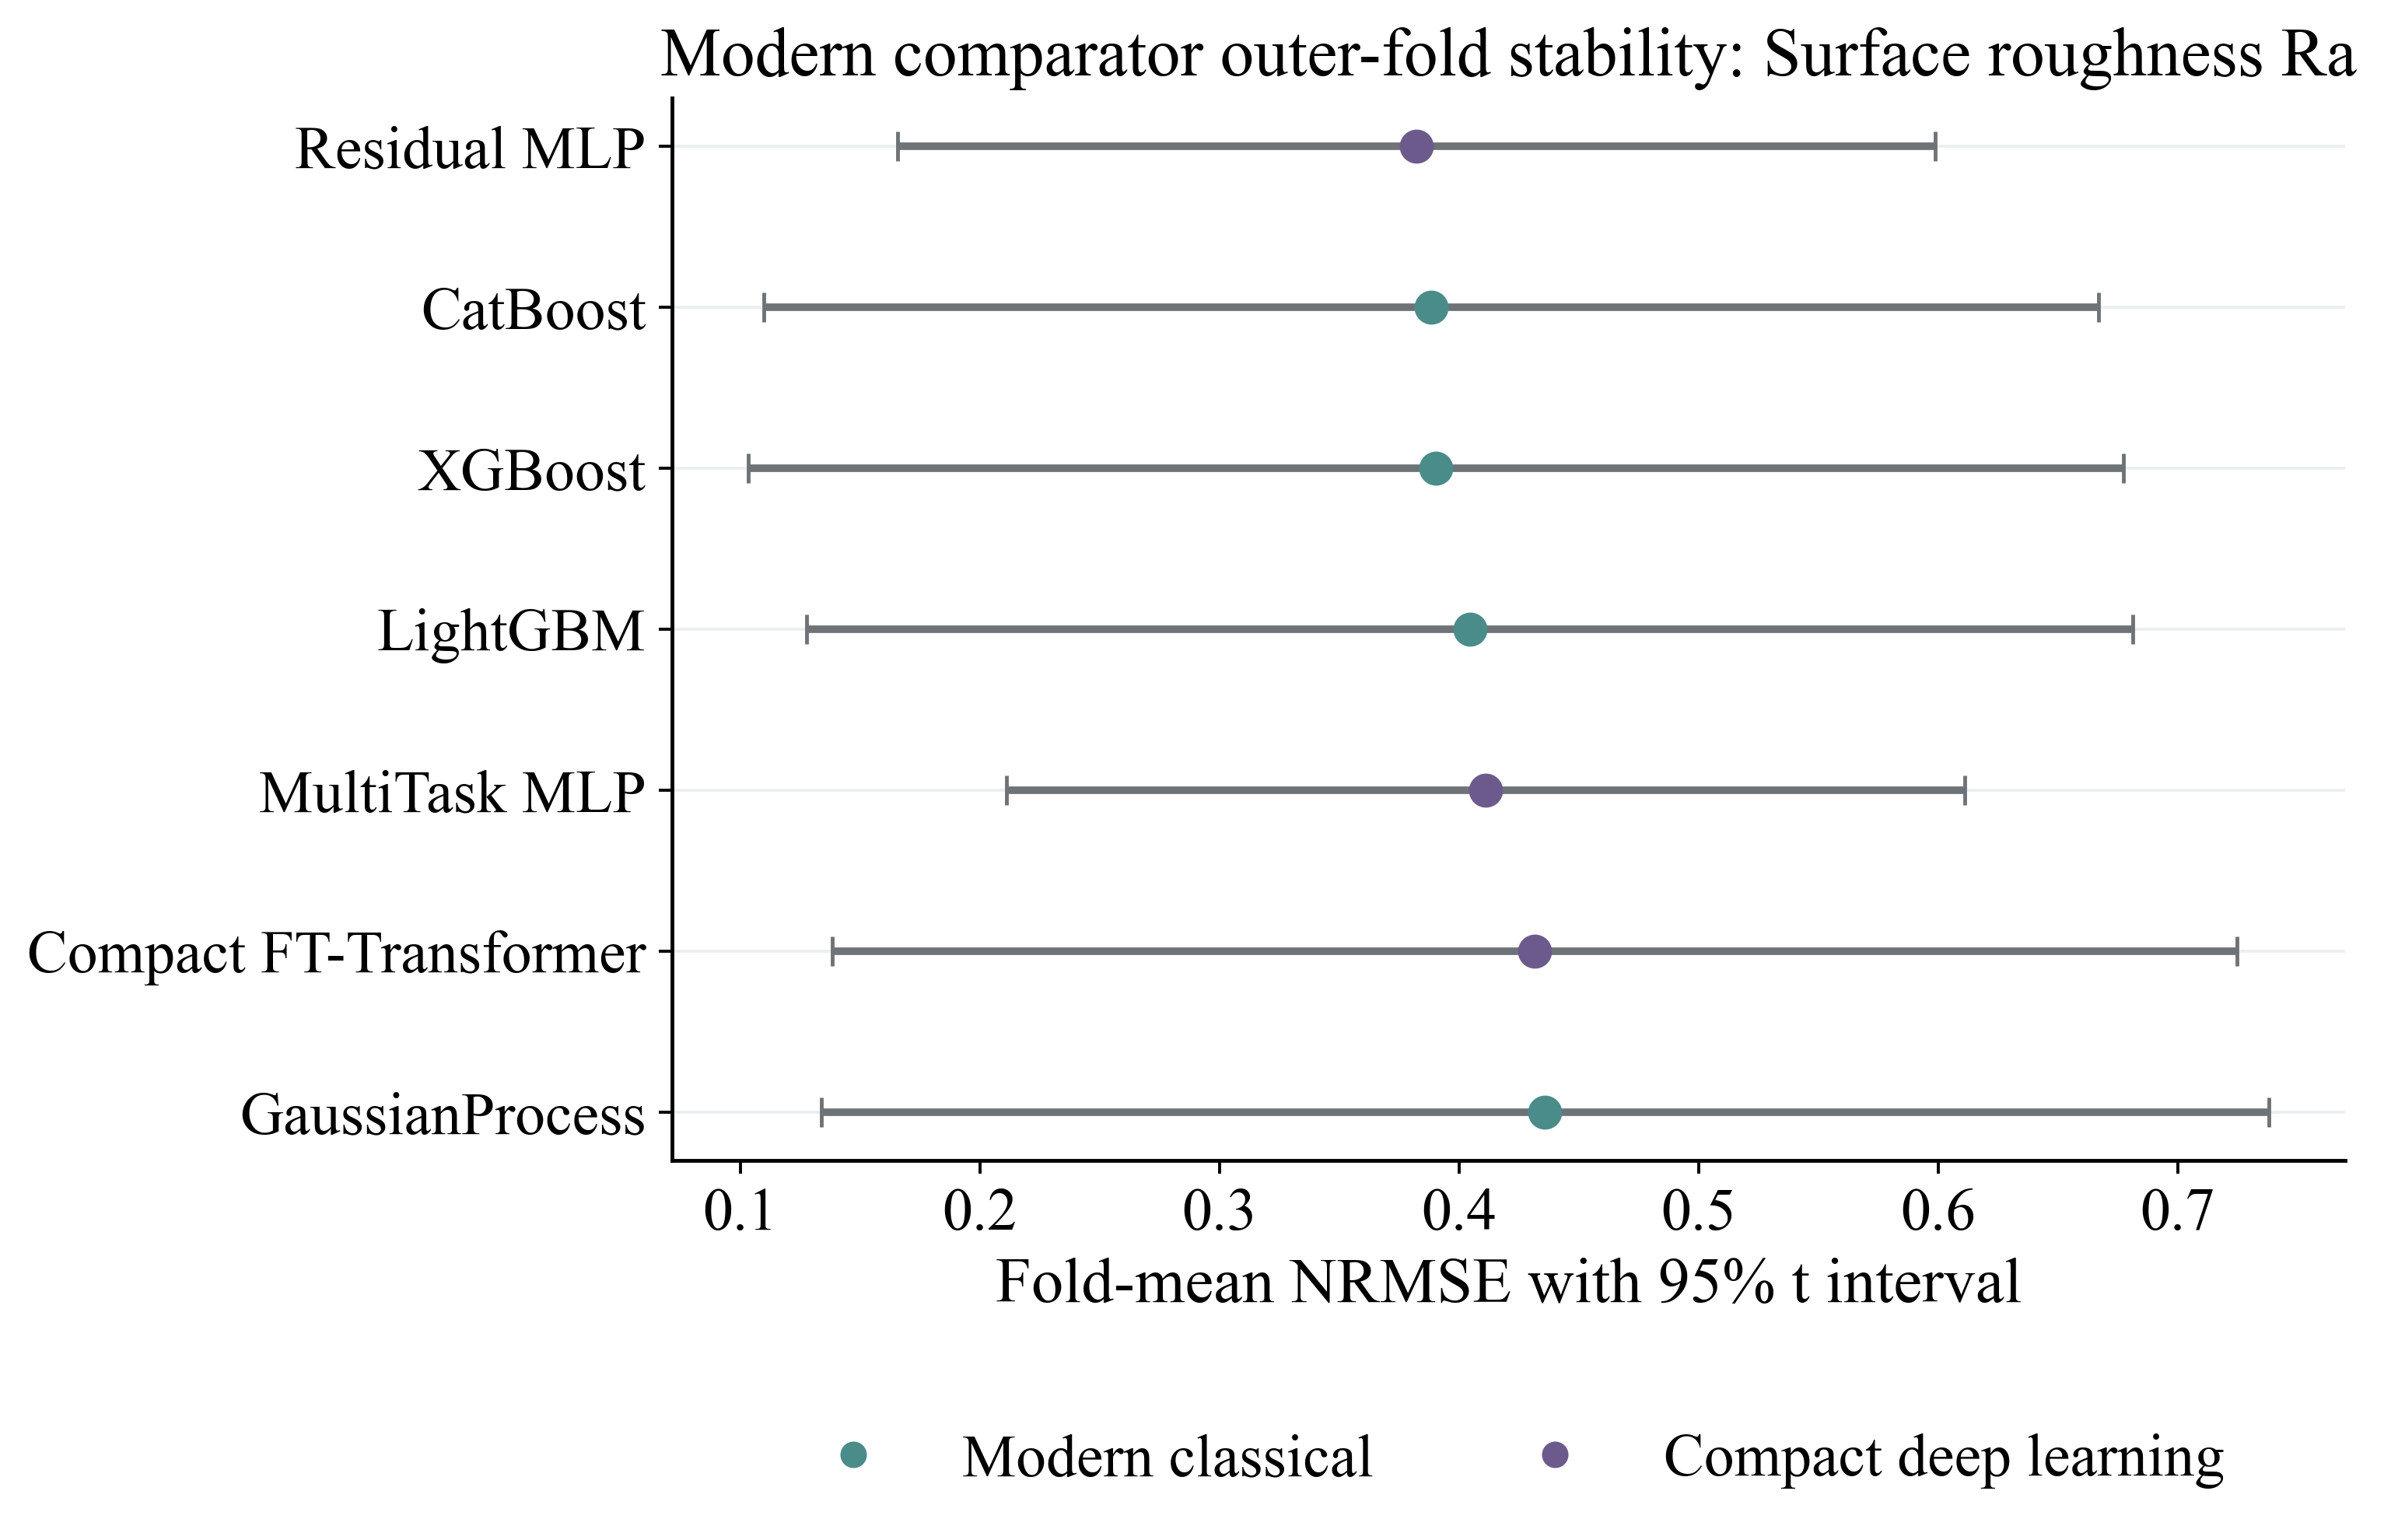

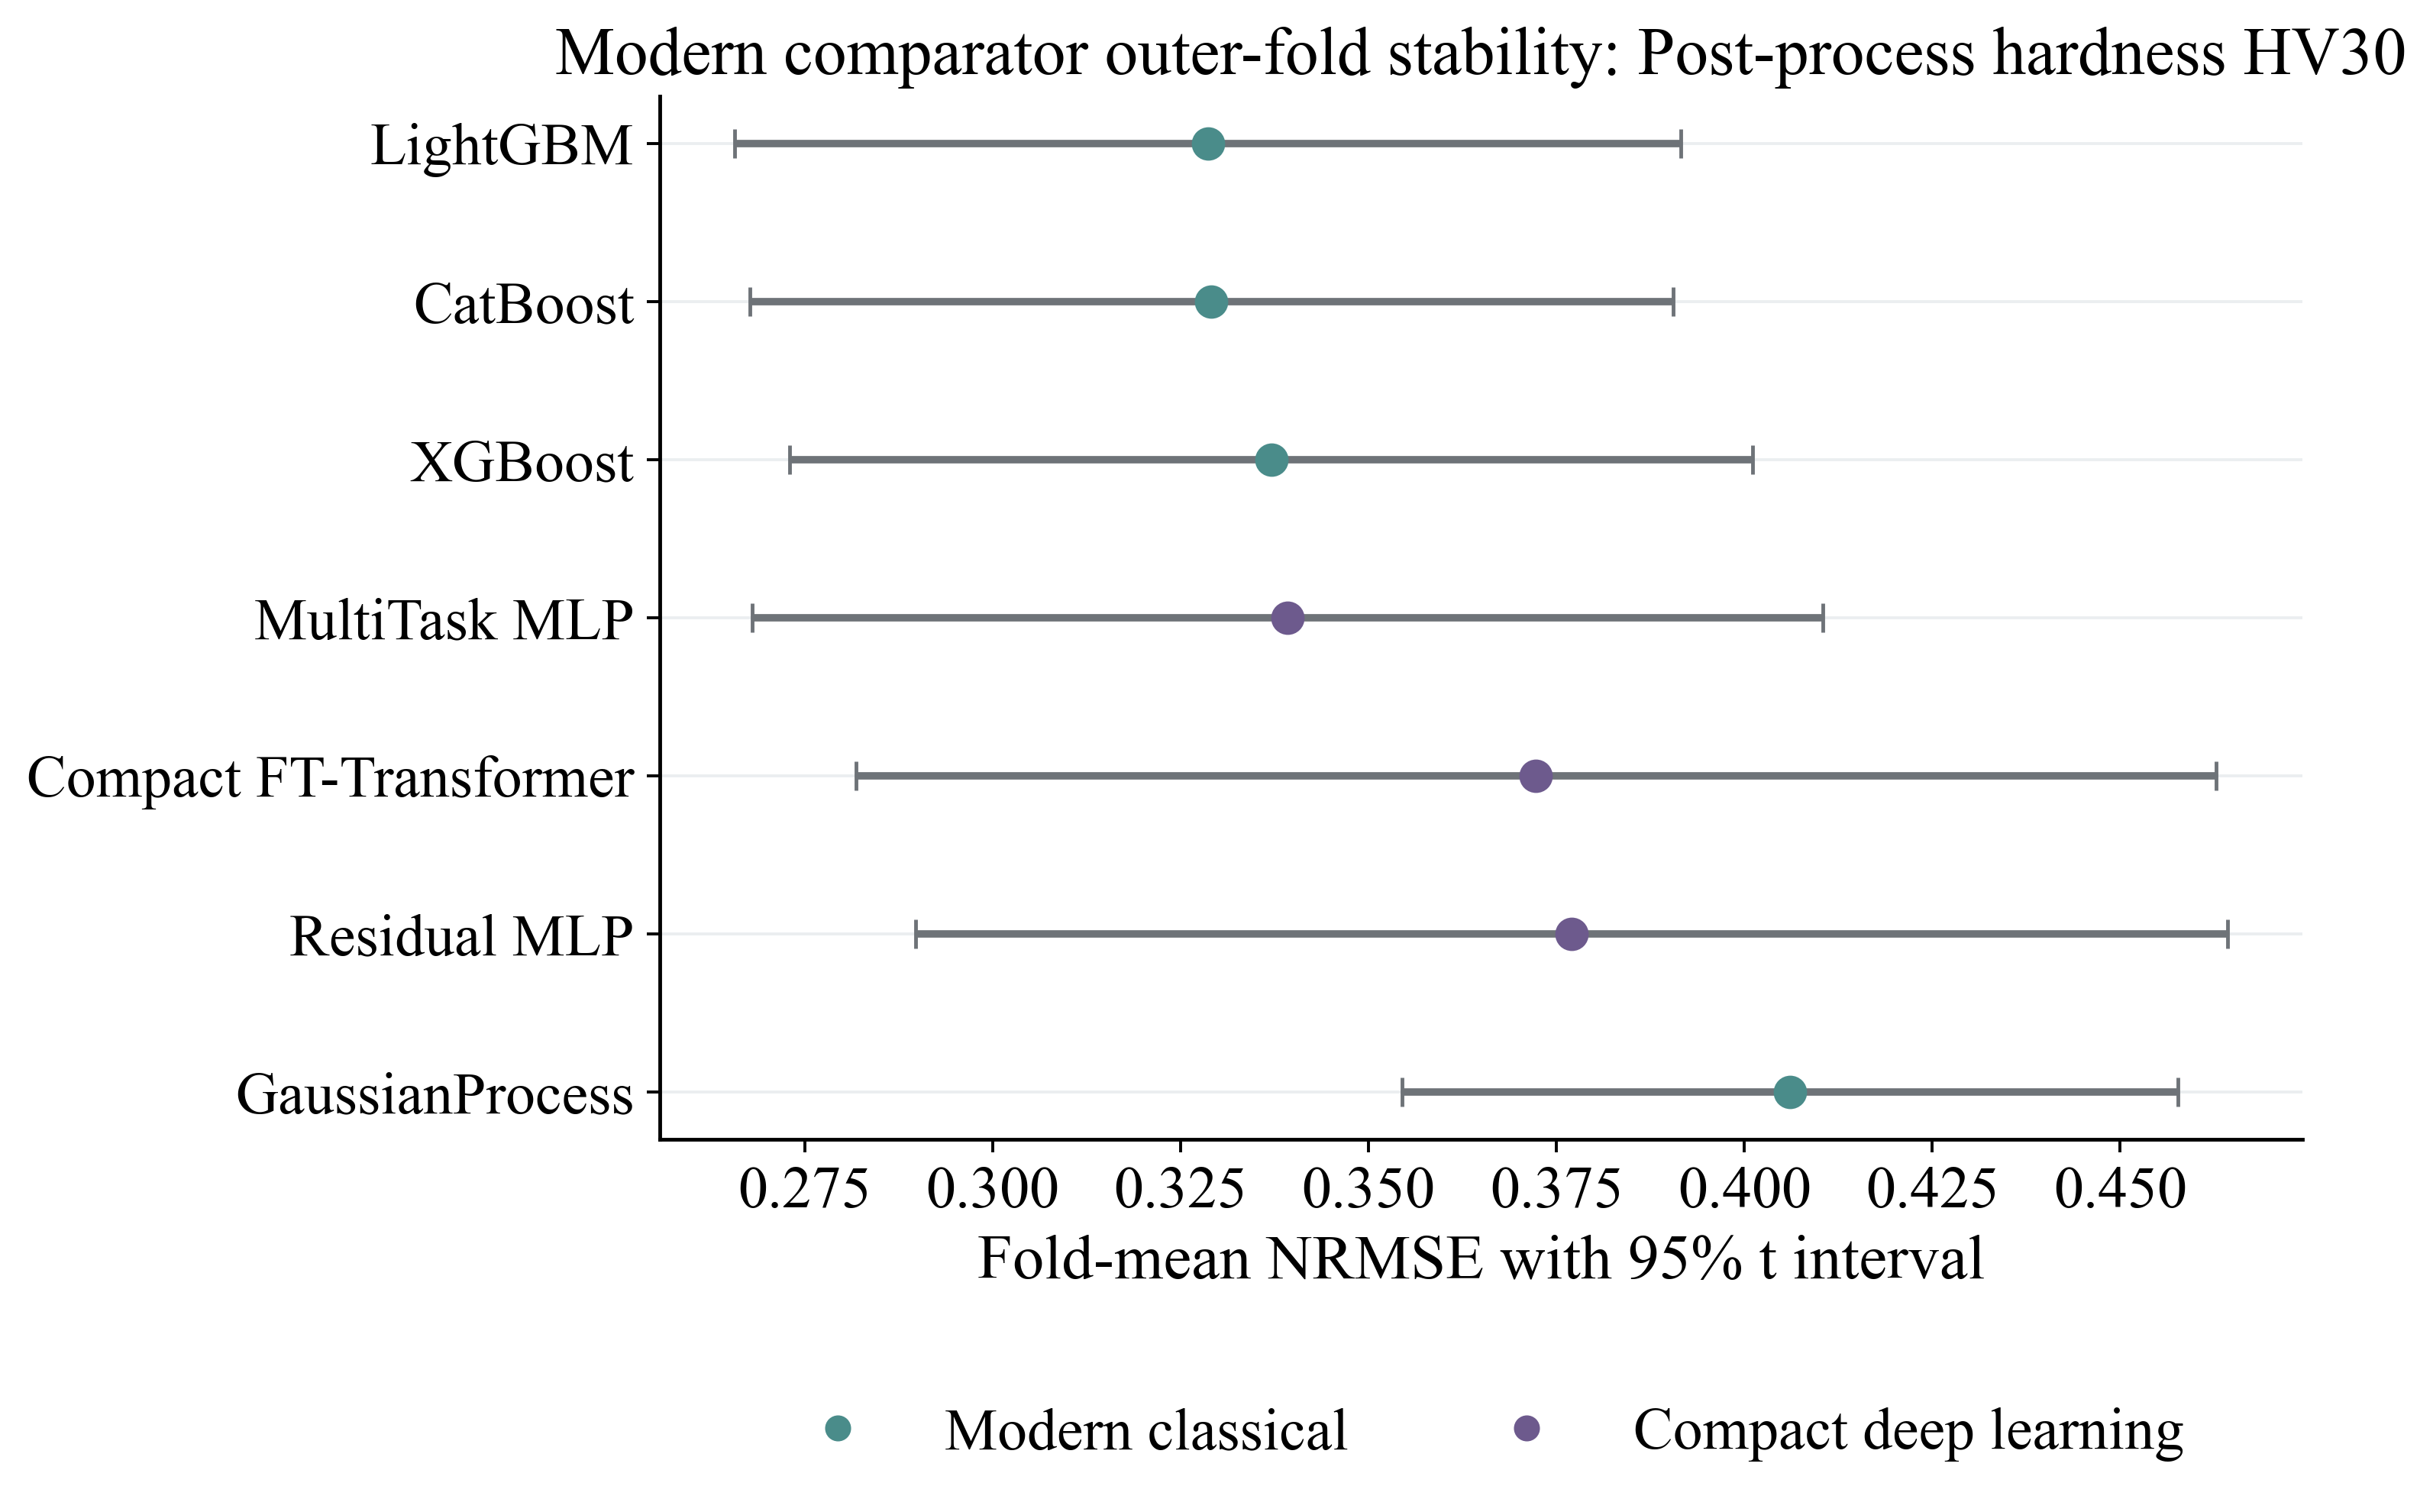

**Interpretation.** `MultiTask MLP` has the lowest modern-comparator point estimate (mean target-wise NRMSE = 0.415). The fold intervals quantify substantial small-sample variability and prevent interpreting a point rank as universal superiority.

In [12]:
from matplotlib.lines import Line2D

target_specs = [
    (TARGETS[0], "Surface roughness Ra", "ra"),
    (TARGETS[1], "Post-process hardness HV30", "hv30"),
]
for target, title, slug in target_specs:
    part = modern_fold_summary[modern_fold_summary.target.eq(target)].sort_values("NRMSE_mean", ascending=False)
    positions = np.arange(len(part))
    colors = [PALETTE["purple"] if model in DL_CONFIGS else PALETTE["teal"] for model in part.model]
    fig, axis = plt.subplots(figsize=(9.6, 6.4))
    for position, (_, row), color in zip(positions, part.iterrows(), colors):
        axis.errorbar(row.NRMSE_mean, position,
                      xerr=[[row.NRMSE_mean-row.NRMSE_95CI_low], [row.NRMSE_95CI_high-row.NRMSE_mean]],
                      fmt="o", color=color, ecolor=PALETTE["gray"], capsize=4, markersize=8)
    axis.set_yticks(positions, labels=part.model)
    axis.set_title(f"Modern comparator outer-fold stability: {title}")
    axis.set_xlabel("Fold-mean NRMSE with 95% t interval")
    axis.set_ylabel("")
    axis.grid(axis="x")
    legend_handles = [
        Line2D([0], [0], marker="o", color="none", markerfacecolor=PALETTE["teal"],
               markeredgecolor=PALETTE["teal"], label="Modern classical"),
        Line2D([0], [0], marker="o", color="none", markerfacecolor=PALETTE["purple"],
               markeredgecolor=PALETTE["purple"], label="Compact deep learning"),
    ]
    axis.legend(handles=legend_handles, loc="lower center", bbox_to_anchor=(0.5, -0.36),
                ncol=2, frameon=False)
    fig.subplots_adjust(left=0.34, right=0.98, top=0.88, bottom=0.27)
    save_scientific_figure(fig, f"modern_fold_nrmse_{slug}", part)
    display(fig)
    plt.close(fig)

display(Markdown(
    f"**Interpretation.** `{modern_ranking.iloc[0].model}` has the lowest modern-comparator "
    f"point estimate (mean target-wise NRMSE = {modern_ranking.iloc[0].mean_NRMSE:.3f}). "
    "The fold intervals quantify substantial small-sample variability and prevent interpreting a point rank as universal superiority."
))

## 10. Deep-learning convergence and seed stability


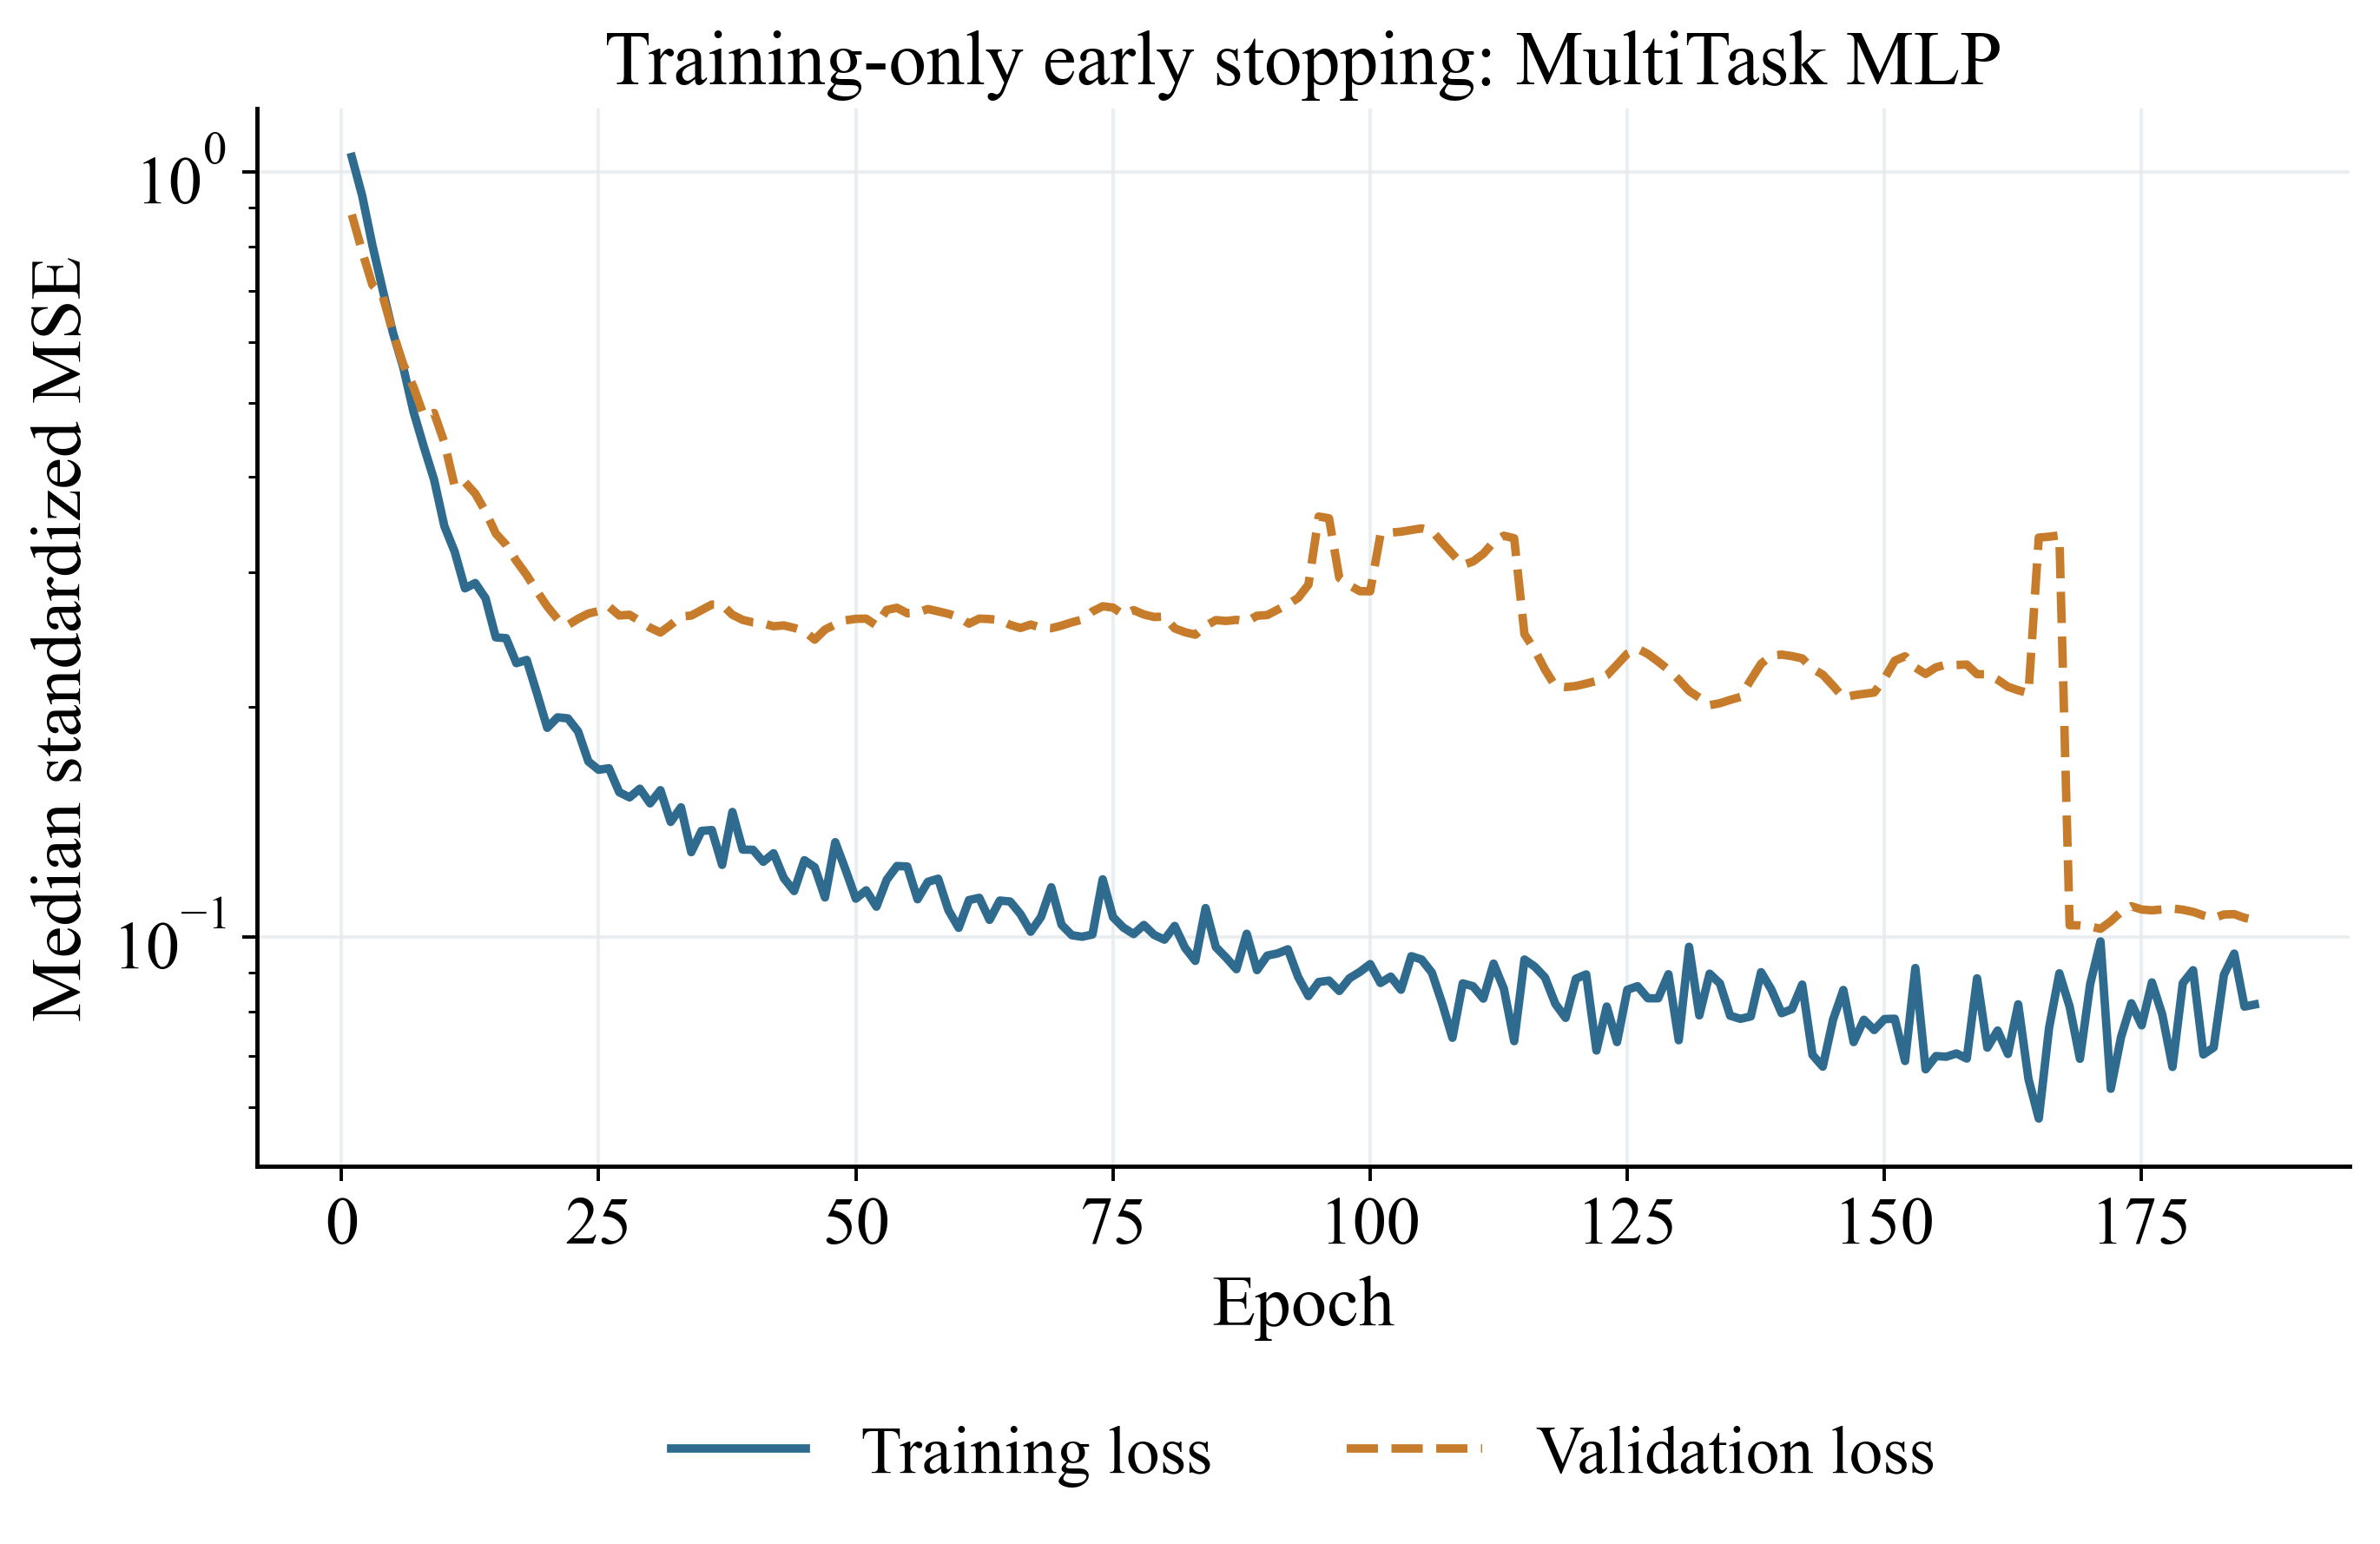

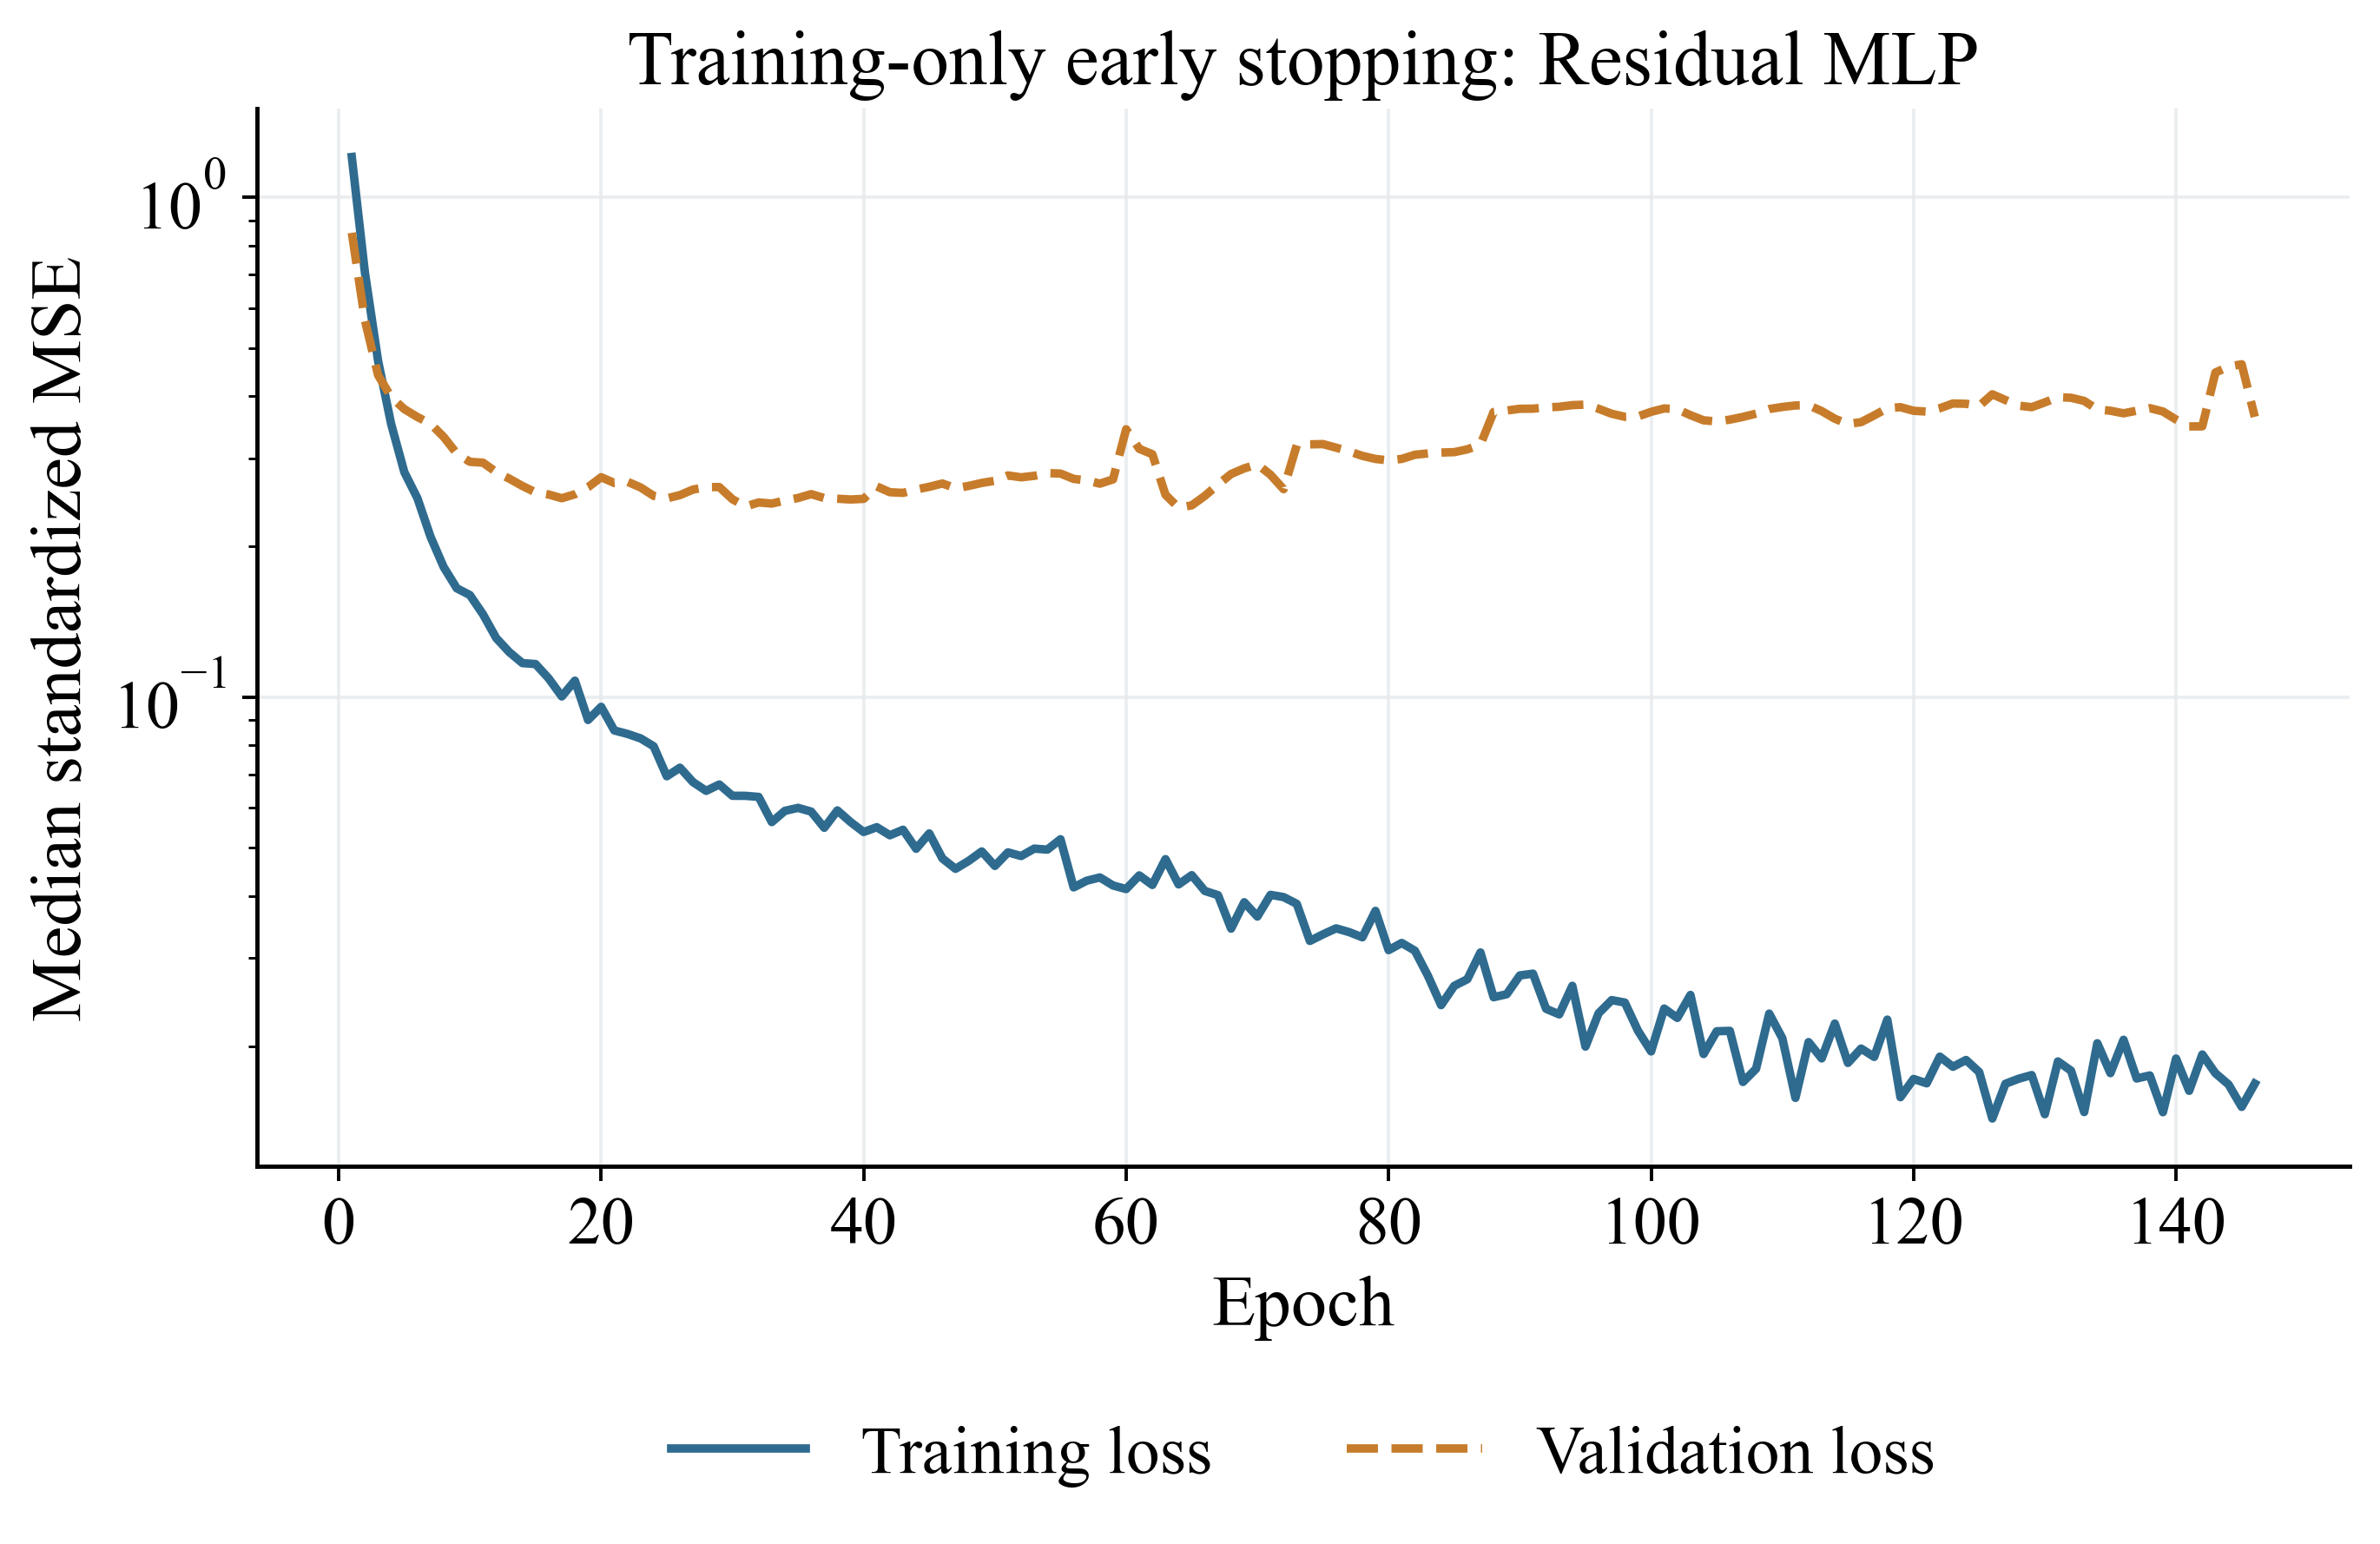

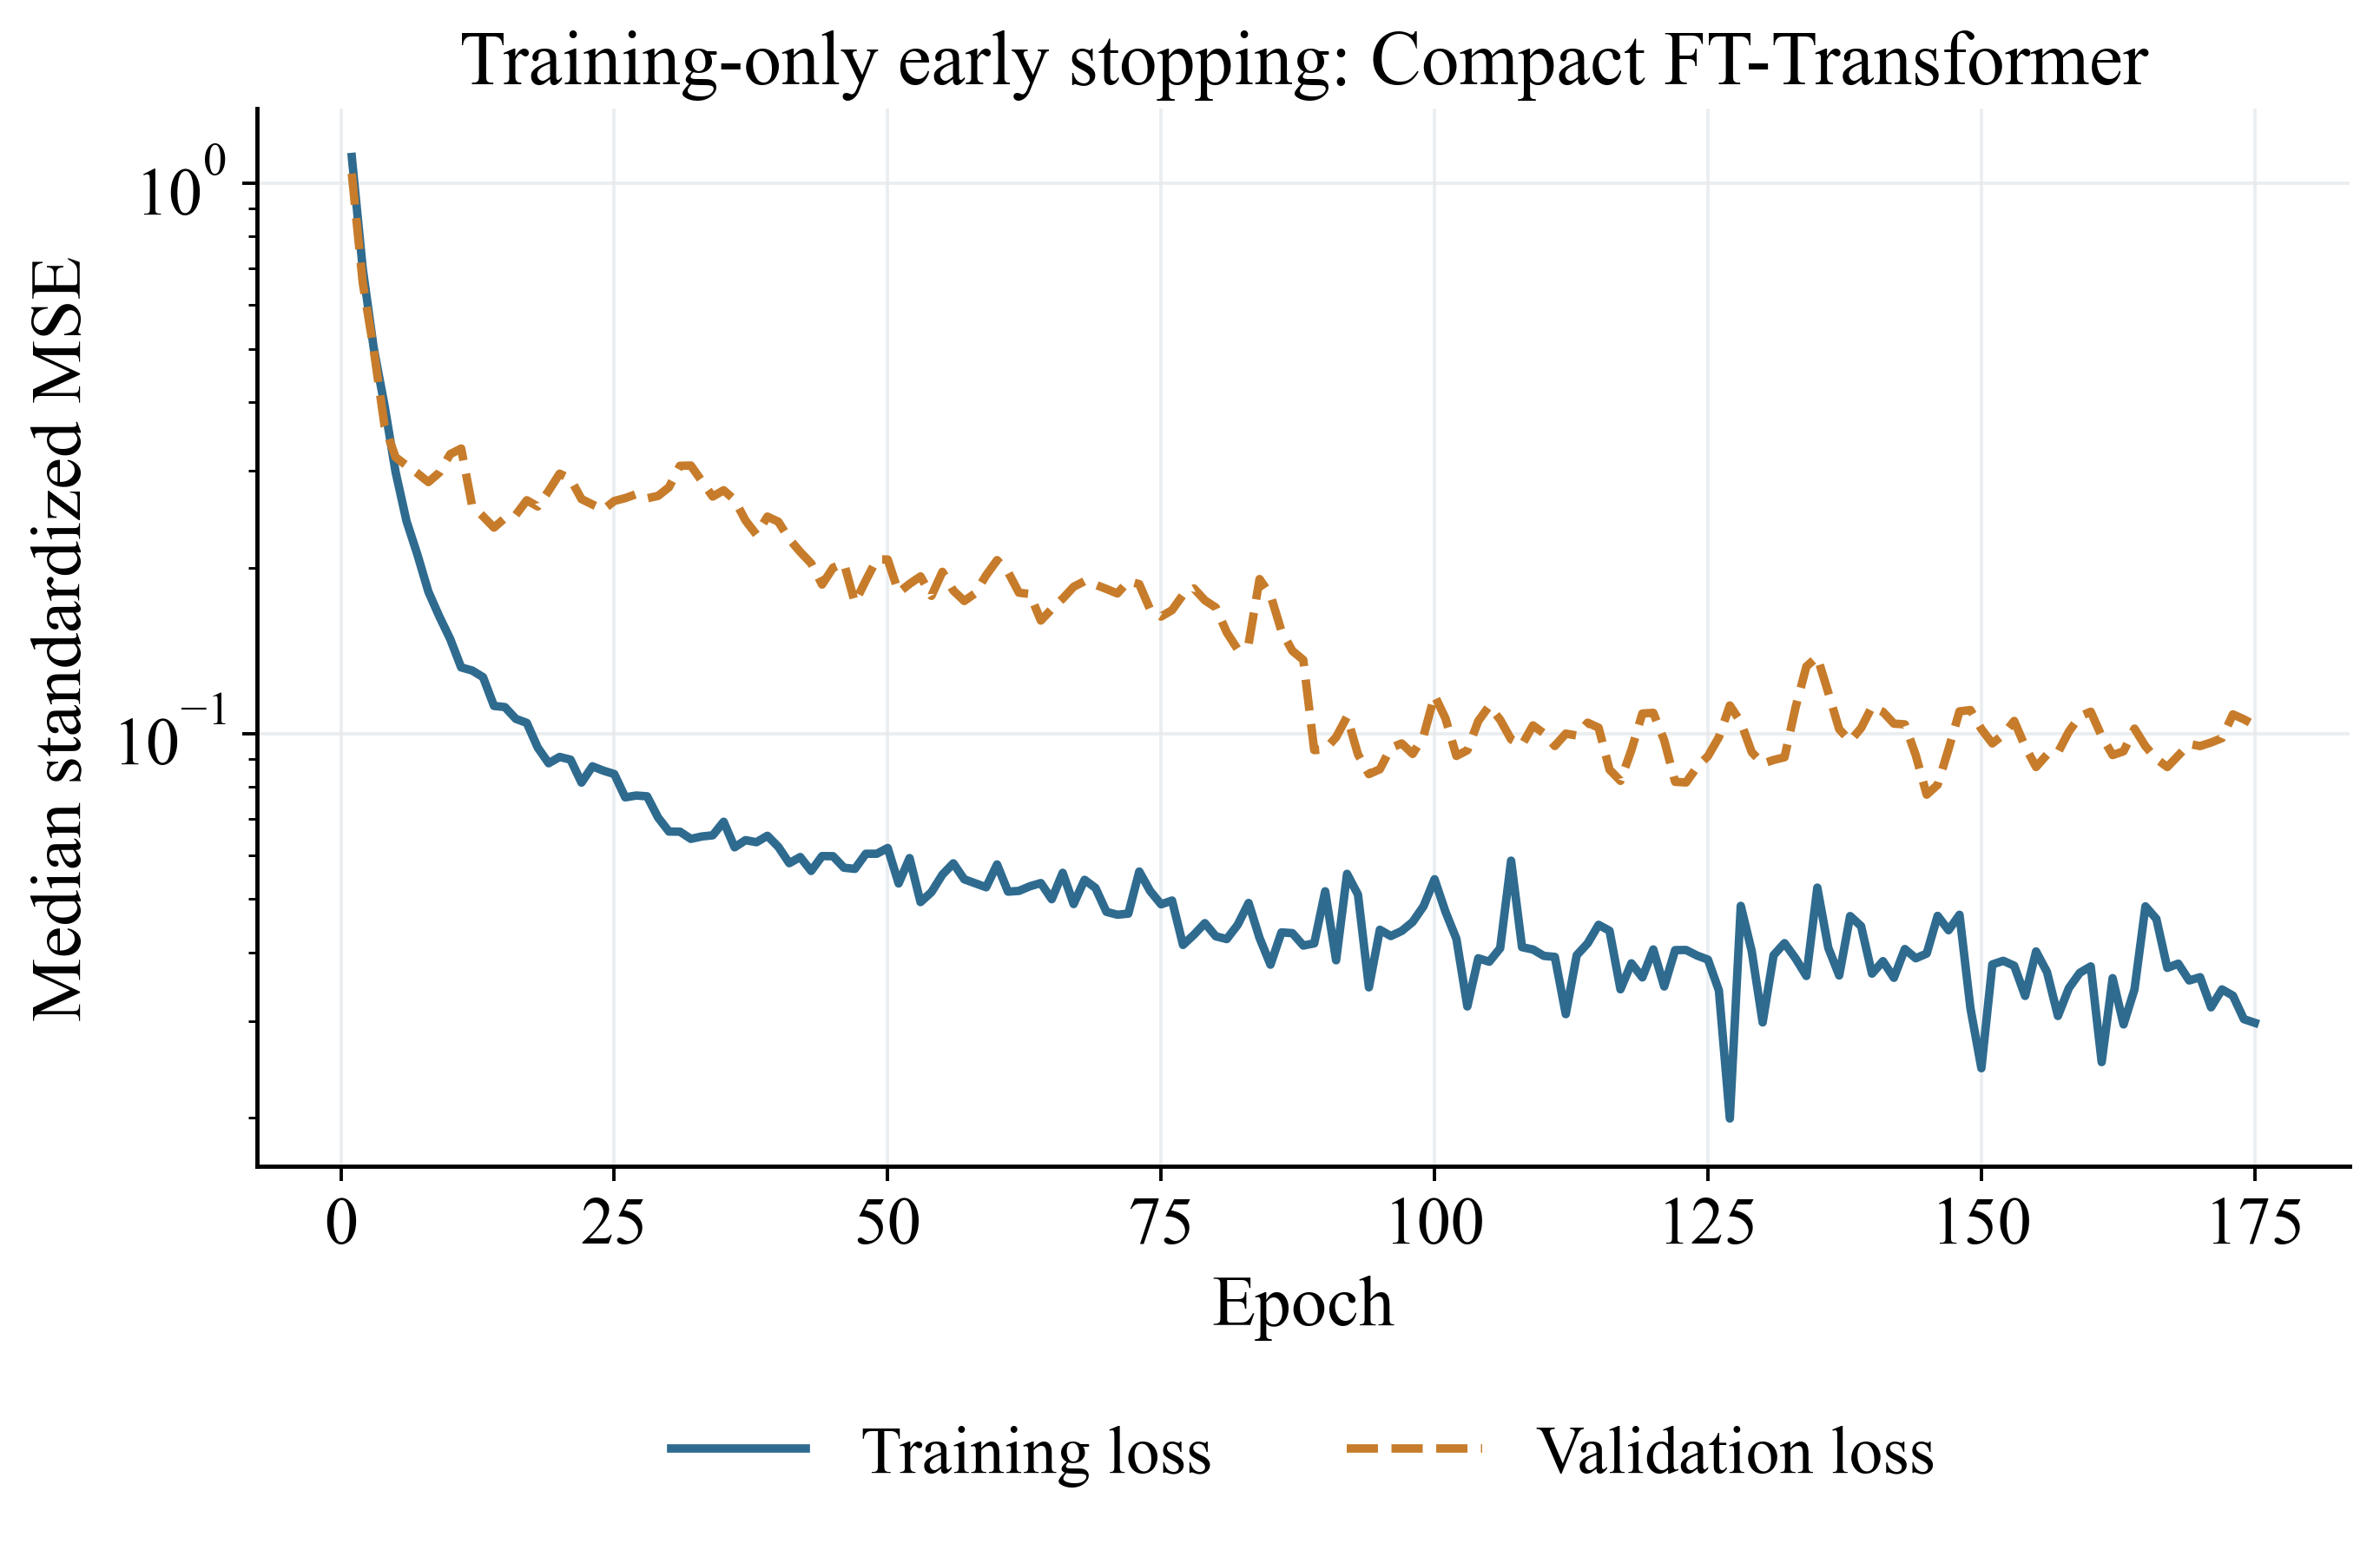

In [13]:
histories = pd.read_csv(METRIC_DIR / "dl_training_histories.csv")
history_summary = histories.groupby(["model", "epoch"], as_index=False).agg(
    median_train_loss=("train_loss", "median"),
    median_validation_loss=("validation_loss", "median"),
    runs=("seed", "size"),
)
model_slugs = {
    "MultiTask MLP": "multitask_mlp",
    "Residual MLP": "residual_mlp",
    "Compact FT-Transformer": "compact_ft_transformer",
}
for model_name in DL_CONFIGS:
    part = history_summary[history_summary.model.eq(model_name)]
    fig, axis = plt.subplots(figsize=(8.4, 5.8))
    axis.plot(part.epoch, part.median_train_loss, color=PALETTE["blue"], label="Training loss")
    axis.plot(part.epoch, part.median_validation_loss, color=PALETTE["orange"], linestyle="--",
              label="Validation loss")
    axis.set_title(f"Training-only early stopping: {model_name}")
    axis.set_xlabel("Epoch")
    axis.set_ylabel("Median standardized MSE")
    axis.set_yscale("log")
    axis.legend(loc="lower center", bbox_to_anchor=(0.5, -0.36), ncol=2, frameon=False)
    fig.subplots_adjust(left=0.16, right=0.98, top=0.88, bottom=0.28)
    save_scientific_figure(fig, f"dl_training_validation_{model_slugs[model_name]}", part)
    display(fig)
    plt.close(fig)

In [14]:
seed_predictions = pd.read_csv(PREDICTION_DIR / "dl_seed_oof_predictions.csv")
seed_rows = []
for (model_name, target, seed), part in seed_predictions.groupby(["model", "target", "seed"]):
    rmse = np.sqrt(mean_squared_error(part.y_true, part.y_pred))
    seed_rows.append({"model": model_name, "target": target, "seed": seed,
                      "NRMSE": rmse / target_scales[target]})
seed_metrics = pd.DataFrame(seed_rows)
seed_summary = seed_metrics.groupby(["model", "target"], as_index=False).agg(
    seeds=("seed", "nunique"), mean_NRMSE=("NRMSE", "mean"), SD_NRMSE=("NRMSE", "std"),
    minimum_NRMSE=("NRMSE", "min"), maximum_NRMSE=("NRMSE", "max")
)
seed_summary.to_csv(METRIC_DIR / "dl_seed_stability_summary.csv", index=False)
display_grouped_table(seed_summary.round(4), "Deep-learning seed stability")
display(Markdown(
    "**Interpretation.** Every compact neural architecture was evaluated with three reproducible "
    "optimization seeds inside every outer fold. Seed spread is reported rather than selecting the "
    "best run, which is essential for an 81-row tabular experiment."
))


**Deep-learning seed stability — Complete table**

model,target,seeds,mean_NRMSE,SD_NRMSE,minimum_NRMSE,maximum_NRMSE
Compact FT-Transformer,post_process_hardness_HV30,3,0.405600,0.026100,0.387400,0.435500
Compact FT-Transformer,surface_roughness_Ra_um,3,0.590700,0.018700,0.569500,0.604900
MultiTask MLP,post_process_hardness_HV30,3,0.366300,0.015200,0.355900,0.383700
MultiTask MLP,surface_roughness_Ra_um,3,0.492600,0.030700,0.474100,0.528000
Residual MLP,post_process_hardness_HV30,3,0.431900,0.043400,0.405000,0.482000
Residual MLP,surface_roughness_Ra_um,3,0.492200,0.027400,0.467200,0.521500


**Interpretation.** Every compact neural architecture was evaluated with three reproducible optimization seeds inside every outer fold. Seed spread is reported rather than selecting the best run, which is essential for an 81-row tabular experiment.

## 11. Accuracy–efficiency evidence for modern comparators


In [15]:
classical_timing = pd.read_csv(METRIC_DIR / "modern_classical_fold_timing.csv").groupby("model", as_index=False).agg(
    mean_fit_seconds=("fit_seconds", "mean"),
    mean_inference_ms_per_sample=("inference_ms_per_sample", "mean"),
    median_complexity=("serialized_bytes", "median"),
)
dl_timing = pd.read_csv(METRIC_DIR / "dl_training_log.csv").groupby("model", as_index=False).agg(
    mean_fit_seconds=("fit_seconds", "mean"),
    mean_inference_ms_per_sample=("inference_ms_per_sample", "mean"),
    median_complexity=("parameter_count", "median"),
)
modern_timing = pd.concat([classical_timing, dl_timing], ignore_index=True)
modern_timing.to_csv(METRIC_DIR / "modern_timing_complexity_summary.csv", index=False)
reloaded_classical = joblib.load(MODEL_DIR / "modern_classical_outer_fold_models.joblib")
reloaded_dl = torch.load(MODEL_DIR / "dl_outer_fold_models.pt", map_location="cpu", weights_only=False)
display_grouped_table(modern_timing.round(4), "Modern-model timing and complexity")


**Modern-model timing and complexity — Complete table**

model,mean_fit_seconds,mean_inference_ms_per_sample,median_complexity
CatBoost,0.008700,0.094500,47612.000000
GaussianProcess,0.011600,0.106100,54011.000000
LightGBM,0.011300,0.103200,207440.000000
XGBoost,0.016500,0.142800,315380.000000
Compact FT-Transformer,0.738100,0.271800,2514.000000
MultiTask MLP,0.791700,0.794700,882.000000
Residual MLP,0.915100,0.125900,4738.000000


## Limitations and hand-off

Compact deep models are intentionally regularized, yet their variance remains material at this sample size. Published tabular architectures are described as compact comparators rather than full-scale SOTA implementations when simplified. Notebook 05 may retain components only when their scientific role and training-side validation contribution are explicit; unfavorable results must remain visible.

No methodologically compatible independent dataset containing the required process structure and paired Ra/HV30 outcomes was identified. Therefore, independent external validation was not performed. The study relies on leakage-safe specimen-grouped nested cross-validation and complementary internal robustness analyses, and all conclusions are restricted to the investigated 51CrV4 factorial domain. Internal model comparison does not replace prospective independent validation.
